# **Étape 1 :Création du dossier et importation du ZIP Kaggle dans Colab**

In [ ]:
import os

os.makedirs("Projet_Olist/data", exist_ok=True)
os.makedirs("Projet_Olist/exports", exist_ok=True)

print("Structure créée")

Structure créée


In [ ]:
#Vérification
os.listdir()

['.config', 'archive (16).zip', 'Projet_Olist', 'sample_data']

In [ ]:
#Importation du Zip kaggle
from google.colab import files

uploaded = files.upload()

Saving archive (16).zip to archive (16).zip


## **Etape 2 : Dézipper le fichier**

In [ ]:
import zipfile
import os

zip_path = "archive (16).zip"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("olist_data")

print("Fichier ZIP extrait avec succès.")

Fichier ZIP extrait avec succès.


# **Etape 3 : Vérification des fichiers disponibles**

In [ ]:
#Vérification du fichier disponible
os.listdir("olist_data")

['olist_order_payments_dataset.csv',
 'olist_geolocation_dataset.csv',
 'olist_order_reviews_dataset.csv',
 'olist_sellers_dataset.csv',
 'olist_customers_dataset.csv',
 'product_category_name_translation.csv',
 'olist_order_items_dataset.csv',
 'olist_products_dataset.csv',
 'olist_orders_dataset.csv']

In [ ]:
#Ajout de Olist_data dans projet Olist
with zipfile.ZipFile("archive (16).zip", "r") as zip_ref:
    zip_ref.extractall("Projet_Olist/data")

# **Étape 4 :Importation des bibliothèques**

In [ ]:
#Chargement des bibliothèques
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)

print("Bibliothèques chargées.")

Bibliothèques chargées.


# **Étape 5 :Chargement des tables principales**

In [ ]:
#Chargement des tables principales
orders = pd.read_csv("olist_data/olist_orders_dataset.csv")
items = pd.read_csv("olist_data/olist_order_items_dataset.csv")
reviews = pd.read_csv("olist_data/olist_order_reviews_dataset.csv")
products = pd.read_csv("olist_data/olist_products_dataset.csv")
customers = pd.read_csv("olist_data/olist_customers_dataset.csv")

# **Etape 6 : Vérification de la taille des tables**

In [ ]:
#Vérification de la taille des tables
print("Orders :", orders.shape)
print("Items :", items.shape)
print("Reviews :", reviews.shape)
print("Products :", products.shape)
print("Customers :", customers.shape)

Orders : (99441, 8)
Items : (112650, 7)
Reviews : (99224, 7)
Products : (32951, 9)
Customers : (99441, 5)


# **Etape 7 : Affichage des aperçus**

In [ ]:
#Affiche des aperçus
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [ ]:
items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [ ]:
reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


# **Etape 8 : Comprehension de la structure des données**

In [ ]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB


In [ ]:
items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  object 
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  object 
 3   seller_id            112650 non-null  object 
 4   shipping_limit_date  112650 non-null  object 
 5   price                112650 non-null  float64
 6   freight_value        112650 non-null  float64
dtypes: float64(2), int64(1), object(4)
memory usage: 6.0+ MB


In [ ]:
reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   review_id                99224 non-null  object
 1   order_id                 99224 non-null  object
 2   review_score             99224 non-null  int64 
 3   review_comment_title     11568 non-null  object
 4   review_comment_message   40977 non-null  object
 5   review_creation_date     99224 non-null  object
 6   review_answer_timestamp  99224 non-null  object
dtypes: int64(1), object(6)
memory usage: 5.3+ MB


In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32951 entries, 0 to 32950
Data columns (total 9 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   product_id                  32951 non-null  object 
 1   product_category_name       32341 non-null  object 
 2   product_name_lenght         32341 non-null  float64
 3   product_description_lenght  32341 non-null  float64
 4   product_photos_qty          32341 non-null  float64
 5   product_weight_g            32949 non-null  float64
 6   product_length_cm           32949 non-null  float64
 7   product_height_cm           32949 non-null  float64
 8   product_width_cm            32949 non-null  float64
dtypes: float64(7), object(2)
memory usage: 2.3+ MB


In [ ]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   customer_id               99441 non-null  object
 1   customer_unique_id        99441 non-null  object
 2   customer_zip_code_prefix  99441 non-null  int64 
 3   customer_city             99441 non-null  object
 4   customer_state            99441 non-null  object
dtypes: int64(1), object(4)
memory usage: 3.8+ MB


# **Etape 9 :Recherche les valeurs manquantes**

In [ ]:
orders.isnull().sum()

,0
order_id,0
customer_id,0
order_status,0
order_purchase_timestamp,0
order_approved_at,160
order_delivered_carrier_date,1783
order_delivered_customer_date,2965
order_estimated_delivery_date,0


In [ ]:
items.isnull().sum()

,0
order_id,0
order_item_id,0
product_id,0
seller_id,0
shipping_limit_date,0
price,0
freight_value,0


In [ ]:
reviews.isnull().sum()

,0
review_id,0
order_id,0
review_score,0
review_comment_title,87656
review_comment_message,58247
review_creation_date,0
review_answer_timestamp,0


In [ ]:
products.isnull().sum()

,0
product_id,0
product_category_name,610
product_name_lenght,610
product_description_lenght,610
product_photos_qty,610
product_weight_g,2
product_length_cm,2
product_height_cm,2
product_width_cm,2


In [ ]:
customers.isnull().sum()

,0
customer_id,0
customer_unique_id,0
customer_zip_code_prefix,0
customer_city,0
customer_state,0


# **Etape 10 : Vérification des doublons**

In [ ]:
print("Orders :", orders.duplicated().sum())
print("Items :", items.duplicated().sum())
print("Reviews :", reviews.duplicated().sum())
print("Products :", products.duplicated().sum())
print("Customers :", customers.duplicated().sum())

Orders : 0
Items : 0
Reviews : 0
Products : 0
Customers : 0


# **Etape 12 : Convertir les dates**

In [ ]:
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"]
)

In [ ]:
#Vérification
orders["order_purchase_timestamp"].dtype

dtype('<M8[ns]')

# **Etape 13 :Création Année et Mois**

In [ ]:
orders["annee"] = orders["order_purchase_timestamp"].dt.year

orders["mois"] = orders["order_purchase_timestamp"].dt.month

In [ ]:
#Vérification
orders[["order_purchase_timestamp", "annee", "mois"]].head()

,order_purchase_timestamp,annee,mois
0,2017-10-02 10:56:33,2017,10
1,2018-07-24 20:41:37,2018,7
2,2018-08-08 08:38:49,2018,8
3,2017-11-18 19:28:06,2017,11
4,2018-02-13 21:18:39,2018,2


# **Etape 14 :Création de la variable Saison**

In [ ]:
def saison(mois):

    if mois in [12, 1, 2]:
        return "Hiver"

    elif mois in [3, 4, 5]:
        return "Printemps"

    elif mois in [6, 7, 8]:
        return "Été"

    else:
        return "Automne"

application

In [ ]:
orders["saison"] = orders["mois"].apply(saison)

Vérification

In [ ]:
orders["saison"].value_counts()

,count
saison,
Été,30573
Printemps,29809
Hiver,22251
Automne,16808


# **Etape 15 :Fusion des tables**

Nous allons construire une table unique contenant :

les commandes ;

les produits ;

les prix ;

les clients ;

les avis clients ;

les saisons.

**Fusion Orders + Order Items**


In [ ]:
df = orders.merge(
    items,
    on="order_id",
    how="inner"
)

df.shape

(112650, 17)

**Ajout des produits**

In [ ]:
df = df.merge(
    products,
    on="product_id",
    how="left"
)

df.shape

(112650, 25)

**Ajout des clients**

In [ ]:
df = df.merge(
    customers,
    on="customer_id",
    how="left"
)

df.shape

(112650, 29)

**Ajout des avis clients**

In [ ]:
df = df.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="left"
)

df.shape

(113314, 30)

**Vérification**

In [ ]:
df.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,annee,mois,saison,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_score
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,2017,10,Automne,1,87285b34884572647811a353c7ac498a,3504c0cb71d7fa48d967e0e4c94d59d9,2017-10-06 11:07:15,29.99,8.72,utilidades_domesticas,40.0,268.0,4.0,500.0,19.0,8.0,13.0,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,4.0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,2018,7,Été,1,595fac2a385ac33a80bd5114aec74eb8,289cdb325fb7e7f891c38608bf9e0962,2018-07-30 03:24:27,118.70,22.76,perfumaria,29.0,178.0,1.0,400.0,19.0,13.0,19.0,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,4.0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,2018,8,Été,1,aa4383b373c6aca5d8797843e5594415,4869f7a5dfa277a7dca6462dcf3b52b2,2018-08-13 08:55:23,159.90,19.22,automotivo,46.0,232.0,1.0,420.0,24.0,19.0,21.0,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,5.0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,2017,11,Automne,1,d0b61bfb1de832b15ba9d266ca96e5b0,66922902710d126a0e7d26b0e3805106,2017-11-23 19:45:59,45.00,27.20,pet_shop,59.0,468.0,3.0,450.0,30.0,10.0,20.0,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,5.0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,2018,2,Hiver,1,65266b2da20d04dbe00c5c2d3bb7859e,2c9e548be18521d1c43cde1c582c6de8,2018-02-19 20:31:37,19.90,8.72,papelaria,38.0,316.0,4.0,250.0,51.0,15.0,15.0,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,5.0


**Etape 16 : Création du chiffre d'affaires**

Dans ce projet nous utiliserons :

CA = prix + frais de livraison

In [ ]:
df["chiffre_affaires"] = (
    df["price"] +
    df["freight_value"]
)

Vérification :

In [ ]:
df[["price", "freight_value", "chiffre_affaires"]].head()

,price,freight_value,chiffre_affaires
0,29.99,8.72,38.71
1,118.70,22.76,141.46
2,159.90,19.22,179.12
3,45.00,27.20,72.20
4,19.90,8.72,28.62


In [ ]:
df["chiffre_affaires"] = (
    df["price"] +
    df["freight_value"]
)

In [ ]:
# Gestion des valeurs manquantes

# Catégorie produit
df["product_category_name"] = df["product_category_name"].fillna(
    "Non renseignée"
)

# Suppression des lignes sans note client
df = df.dropna(
    subset=["review_score"]
)

In [ ]:
df["review_score"].isnull().sum()

np.int64(0)

# **Etape 17 — Contrôle final**

Dimensionns:

In [ ]:
print(df.shape)

(112372, 31)


Valeurs manquantes:

In [ ]:
df.isnull().sum().sort_values(ascending=False).head(20)

,0
order_delivered_customer_date,2360
product_description_lenght,1598
product_name_lenght,1598
product_photos_qty,1598
order_delivered_carrier_date,1184
product_weight_g,18
product_length_cm,18
product_height_cm,18
product_width_cm,18
order_approved_at,15


**Vérifier les statistiques du chiffre d'affaires**

In [ ]:
df["chiffre_affaires"].describe()

,chiffre_affaires
count,112372.000000
mean,140.356714
std,189.212307
min,6.080000
25%,55.177500
50%,92.210000
75%,157.790000
max,6929.310000


**Vérifier les saisons**

In [ ]:
df["saison"].value_counts()

,count
saison,
Été,34353
Printemps,33805
Hiver,25055
Automne,19159


**Vérifier la satisfaction client**

In [ ]:
df["review_score"].describe()

,review_score
count,112372.000000
mean,4.032473
std,1.387849
min,1.000000
25%,4.000000
50%,5.000000
75%,5.000000
max,5.000000


**Vérification du chiffre d'affaires total**

In [ ]:
print(
    "Nombre de commandes :",
    df["order_id"].nunique()
)

Nombre de commandes : 97917


**Vérifier les catégories de produits**

In [ ]:
print(
    "Nombre de catégories :",
    df["product_category_name"].nunique()
)

Nombre de catégories : 74


**Vérification finale globale**

In [ ]:
print("Résumé final")

print("--------------------")

print("Dimensions :", df.shape)

print(
    "CA total :",
    round(df["chiffre_affaires"].sum(), 2)
)

print(
    "Nombre de commandes :",
    df["order_id"].nunique()
)

print(
    "Nombre de produits :",
    df["product_id"].nunique()
)

print(
    "Satisfaction moyenne :",
    round(
        df["review_score"].mean(),
        2
    )
)

Résumé final
--------------------
Dimensions : (112372, 31)
CA total : 15772164.69
Nombre de commandes : 97917
Nombre de produits : 32789
Satisfaction moyenne : 4.03


**Export du dataset nettoyé**

In [ ]:
df.to_csv(
    "olist_cleaned.csv",
    index=False
)

print(
    "Dataset exporté avec succès."
)

Dataset exporté avec succès.


In [ ]:
from google.colab import files

files.download(
    "olist_cleaned.csv"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Visualisations**

# **Etape 19 : Chiffre d'affaires par saison**

In [ ]:
ca_saison = (
    df.groupby("saison")["chiffre_affaires"]
      .sum()
      .reset_index()
)

ca_saison

,saison,chiffre_affaires
0,Automne,2716682.07
1,Hiver,3369519.30
2,Printemps,4866568.18
3,Été,4819395.14


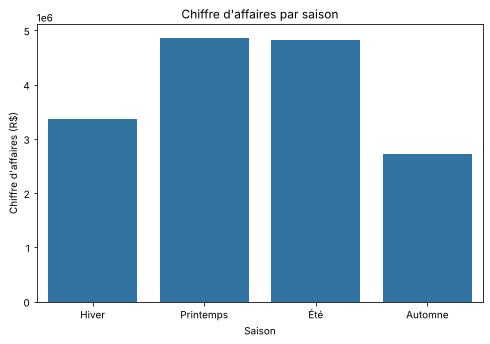

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8,5))

ordre = ["Hiver", "Printemps", "Été", "Automne"]

sns.barplot(
    data=ca_saison,
    x="saison",
    y="chiffre_affaires",
    order=ordre
)

plt.title("Chiffre d'affaires par saison")
plt.xlabel("Saison")
plt.ylabel("Chiffre d'affaires (R$)")

plt.show()

**Volume des ventes par saison**

In [ ]:
volume_saison = (
    df.groupby("saison")["order_id"]
      .count()
      .reset_index()
)

volume_saison

,saison,order_id
0,Automne,19159
1,Hiver,25055
2,Printemps,33805
3,Été,34353


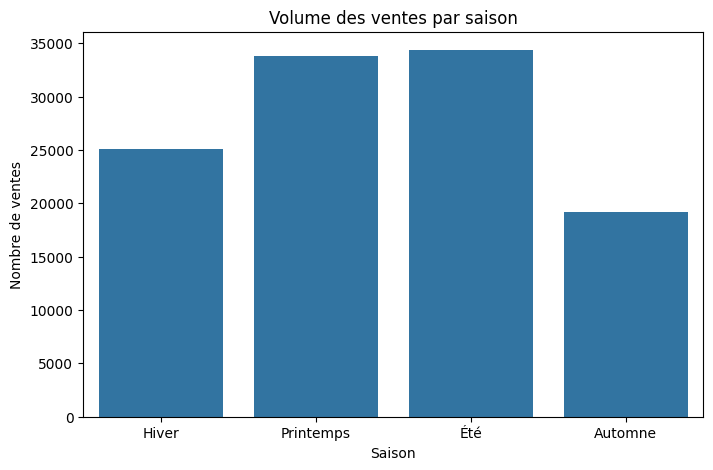

In [ ]:
plt.figure(figsize=(8,5))

ordre = ["Hiver", "Printemps", "Été", "Automne"]

sns.barplot(
    data=volume_saison,
    x="saison",
    y="order_id",
    order=ordre
)

plt.title("Volume des ventes par saison")
plt.xlabel("Saison")
plt.ylabel("Nombre de ventes")

plt.show()

On remarque que l’été a le plus grand volume de ventes, mais que le printemps a le meilleur chiffre d’affaires.
Cela veut dire qu’en été il y a un peu plus de ventes, mais qu’au printemps les commandes génèrent légèrement plus de valeur.

**satisfaction moyenne par saison**

In [ ]:
satisfaction_saison = (
    df.groupby("saison")["review_score"]
      .mean()
      .reset_index()
)

satisfaction_saison

,saison,review_score
0,Automne,3.975312
1,Hiver,3.901537
2,Printemps,3.997012
3,Été,4.194743


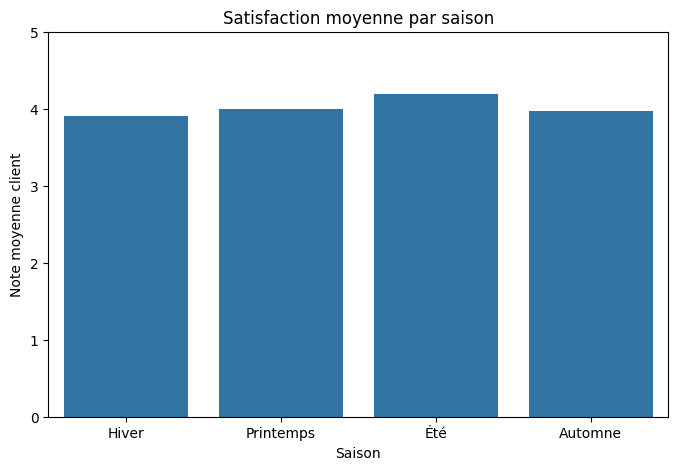

In [ ]:
plt.figure(figsize=(8,5))

ordre = ["Hiver", "Printemps", "Été", "Automne"]

sns.barplot(
    data=satisfaction_saison,
    x="saison",
    y="review_score",
    order=ordre
)

plt.title("Satisfaction moyenne par saison")
plt.xlabel("Saison")
plt.ylabel("Note moyenne client")

plt.ylim(0, 5)

plt.show()

La meilleure satisfaction est en été avec une note moyenne de 4,19/5.
L’hiver est la saison avec la satisfaction la plus faible : 3,90/5.



**distribution des notes clients**

In [ ]:
df["review_score"].value_counts().sort_index()

,count
review_score,
1.0,14235
2.0,3874
3.0,9423
4.0,21315
5.0,63525


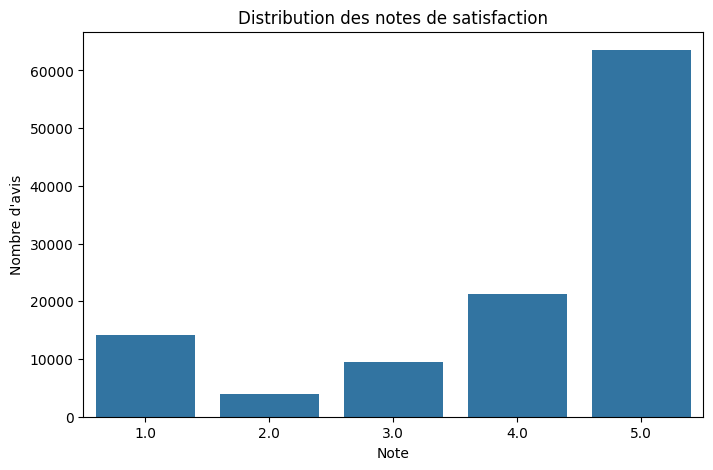

In [ ]:
plt.figure(figsize=(8,5))

sns.countplot(
    data=df,
    x="review_score"
)

plt.title("Distribution des notes de satisfaction")
plt.xlabel("Note")
plt.ylabel("Nombre d'avis")

plt.show()

Ces résultats sont très intéressants parce qu'ils montrent clairement que la majorité des clients sont satisfaits.

**Top 10 catégories de produits**

In [ ]:
top_categories = (
    df.groupby("product_category_name")["chiffre_affaires"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

top_categories

,product_category_name,chiffre_affaires
0,beleza_saude,1434501.78
1,relogios_presentes,1297404.23
2,cama_mesa_banho,1244950.00
3,esporte_lazer,1155295.28
4,informatica_acessorios,1062184.42
5,moveis_decoracao,902472.18
6,utilidades_domesticas,775827.36
7,cool_stuff,712954.07
8,automotivo,678859.45
9,ferramentas_jardim,581483.25


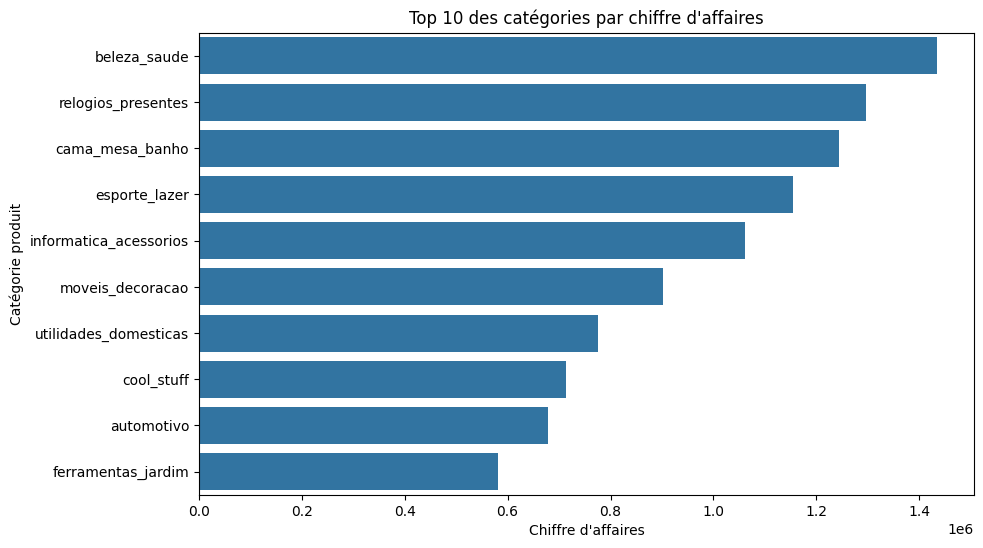

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_categories,
    y="product_category_name",
    x="chiffre_affaires"
)

plt.title("Top 10 des catégories par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires")
plt.ylabel("Catégorie produit")

plt.show()

La catégorie qui génère le plus de CA est beleza_saude avec environ 1,43 M. Ensuite on retrouve relogios_presentes, cama_mesa_banho et esporte_lazer.

**corrélation entre satisfaction et chiffre d’affaires**

In [ ]:
correlation = df[["price", "freight_value", "chiffre_affaires", "review_score"]].corr()

correlation

,price,freight_value,chiffre_affaires,review_score
price,1.000000,0.412707,0.997110,-0.003941
freight_value,0.412707,1.000000,0.480714,-0.036179
chiffre_affaires,0.997110,0.480714,1.000000,-0.006811
review_score,-0.003941,-0.036179,-0.006811,1.000000


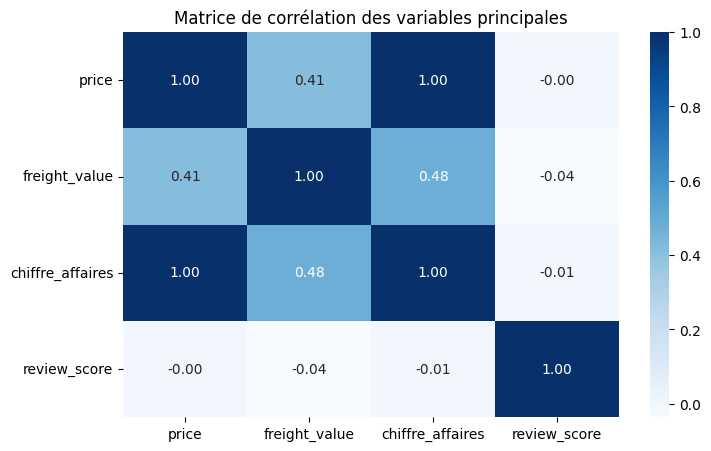

In [ ]:
plt.figure(figsize=(8,5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Matrice de corrélation des variables principales")

plt.show()

Interprétation:
Cela veut dire qu’il n’y a presque pas de relation linéaire directe entre la note client et le chiffre d’affaires au niveau des lignes de commande.

**panier moyen par saison**

In [ ]:
panier_saison = (
    df.groupby("saison")["chiffre_affaires"]
      .mean()
      .reset_index()
)

panier_saison

,saison,chiffre_affaires
0,Automne,141.796653
1,Hiver,134.484905
2,Printemps,143.960011
3,Été,140.290372


Le printemps a le panier moyen le plus élevé, ce qui explique pourquoi il a le meilleur chiffre d’affaires même si l’été a un peu plus de ventes.

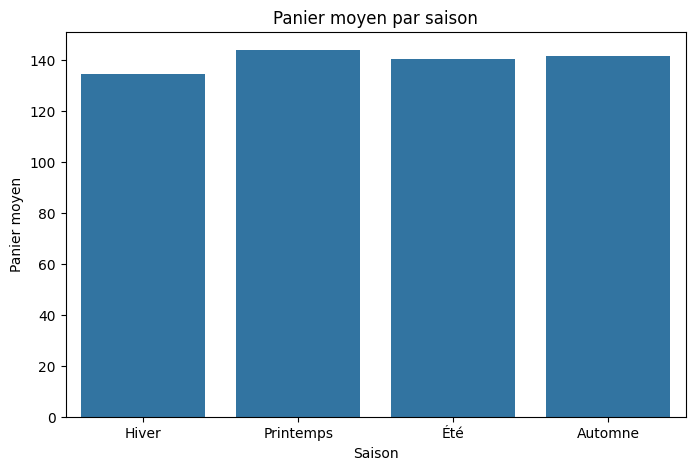

In [ ]:
plt.figure(figsize=(8,5))

ordre = ["Hiver", "Printemps", "Été", "Automne"]

sns.barplot(
    data=panier_saison,
    x="saison",
    y="chiffre_affaires",
    order=ordre
)

plt.title("Panier moyen par saison")
plt.xlabel("Saison")
plt.ylabel("Panier moyen")

plt.show()

# **Analyse des ventes par année**

Comme le dataset couvre 2016 à 2018, il est intéressant de montrer l'évolution de l'activité.

In [ ]:
ca_annee = (
    df.groupby("annee")["chiffre_affaires"]
      .sum()
      .reset_index()
)

ca_annee

,annee,chiffre_affaires
0,2016,56403.77
1,2017,7113582.64
2,2018,8602178.28


L'année 2016 ne couvre pas une année complète dans le dataset Olist. Les résultats de 2016 doivent donc être interprétés avec prudence et ne peuvent pas être directement comparés aux années suivantes.

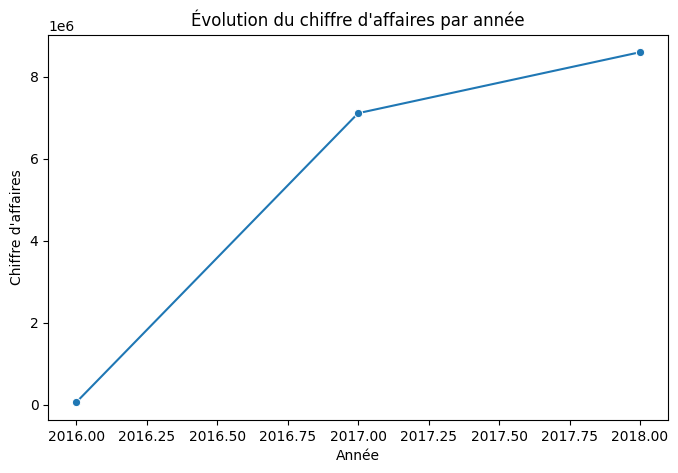

In [ ]:
plt.figure(figsize=(8,5))

sns.lineplot(
    data=ca_annee,
    x="annee",
    y="chiffre_affaires",
    marker="o"
)

plt.title("Évolution du chiffre d'affaires par année")
plt.xlabel("Année")
plt.ylabel("Chiffre d'affaires")

plt.show()

**Satisfaction moyenne par catégorie**

In [ ]:
top_satisfaction = (
    df.groupby("product_category_name")["review_score"]
      .mean()
      .sort_values(ascending=False)
      .head(10)
      .reset_index()
)

top_satisfaction

,product_category_name,review_score
0,cds_dvds_musicais,4.642857
1,fashion_roupa_infanto_juvenil,4.500000
2,livros_interesse_geral,4.446266
3,construcao_ferramentas_ferramentas,4.444444
4,flores,4.419355
5,livros_importados,4.400000
6,livros_tecnicos,4.368421
7,alimentos_bebidas,4.315412
8,malas_acessorios,4.315257
9,portateis_casa_forno_e_cafe,4.302632


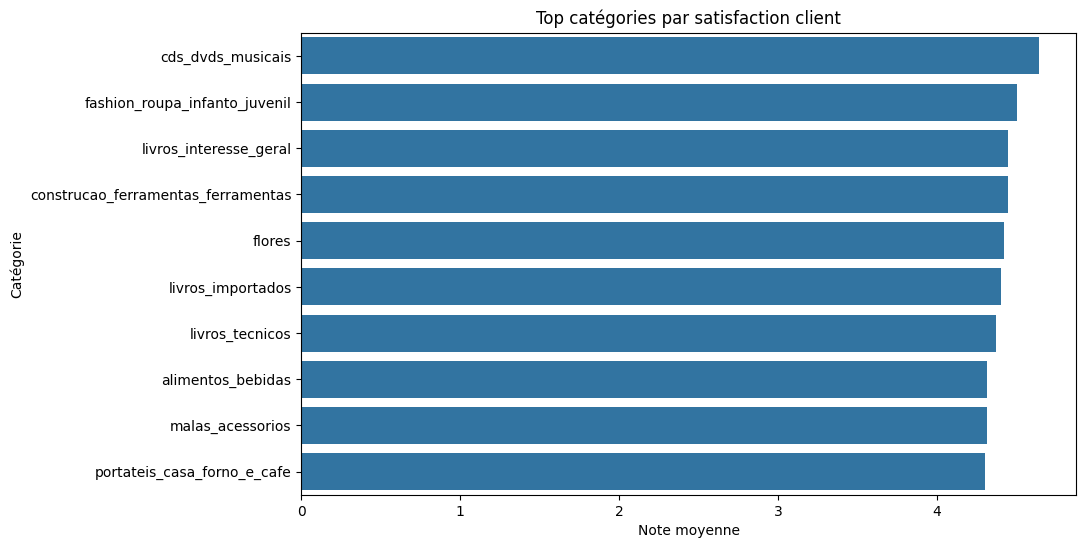

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=top_satisfaction,
    x="review_score",
    y="product_category_name"
)

plt.title("Top catégories par satisfaction client")
plt.xlabel("Note moyenne")
plt.ylabel("Catégorie")

plt.show()